# House Stage 1 regression

The formula is the model: `run_ols(formula, train_years, eval_years)` fits it with `smf.ols(formula, data=train).fit()` and returns the native statsmodels result as `result.model`. It is the same function as `python -m experiments.house.run` (see `experiments/house/run.py`). Shared data prep, validation, and metrics are in `experiments/house/evaluation.py`, and saved runs in `experiments/house/tracking.py`. Holdout years: `src/house/regression/config.py`. Columns: `src/house/regression/schema.py`.
Build the predictors and targets first: `python data-processing/house/house_features.py` (`modeling.csv`) and `python data-processing/house/house_targets.py` (`targets.csv`).
Imputed targets are never trained on. Evaluation scores `non_imputed` (primary), `imputed`, and `all` from the same predictions. Every left-out row is listed with its reason in `result.excluded`. Nothing is saved unless you ask (`save=True` or `tracking.save_run`).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("../../src").resolve()))
sys.path.insert(0, str(Path("../..").resolve()))  # repository root, for experiments.house
import house.regression as hr  # hr.<Tab> lists everything; names are in src/house/regression/__init__.py
from experiments.house import evaluation, tracking
from experiments.house.run import run_ols

In [2]:
import warnings

with warnings.catch_warnings(action="ignore"):  # loading warns with the same summaries printed below
    predictors = hr.load_predictors()  # data/processed/house/modeling.csv, every year (2006-2026)
    targets = hr.load_targets()        # data/processed/house/targets.csv, every year (2006-2024)
print(hr.validate_schema(predictors).summary())  # .issues lists every affected key

In [3]:
print(hr.validate_schema(targets, schema=hr.TARGETS_SCHEMA).summary())

In [4]:
FORMULA = "adj_margin_2p_norm ~ gen_margin_raw + partisan_lean + inc_signed"
TRAIN_YEARS = [2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020]
EVAL_YEARS = [2022]     # scored against actual targets
PREDICT_YEARS = []      # predicted only, no metrics, e.g. [2026] for a forecast
USE_HOLDOUT = False     # True allows HOLDOUT_YEARS (2024) in training, evaluation, or prediction
REQUIRE_COMPLETE = []   # extra columns a row must have, so runs with different formulas share rows

result = run_ols(
    formula=FORMULA,
    train_years=TRAIN_YEARS,
    eval_years=EVAL_YEARS,
    predict_years=PREDICT_YEARS,
    predictors=predictors,  # the tables loaded above, instead of reloading per run
    targets=targets,
    use_holdout=USE_HOLDOUT,
    require_complete=REQUIRE_COMPLETE,
    name="classic_ols",
    save=False,             # True writes results/house/runs/<run_id>
)
print(tracking.describe(result))  # result.config has the raw values

estimator         ols
formula           adj_margin_2p_norm ~ gen_margin_raw + partisan_lean + inc_signed
target            adj_margin_2p_norm
name              classic_ols
train_years       2006, 2008, 2010, 2012, 2014, 2016, 2018, 2020
eval_years        2022
predict_years     -
variables         basic_f: [gen_margin_raw, partisan_lean, inc_signed]
require_complete  -
use_holdout       False (HOLDOUT_YEARS: [2024])
train             3083 rows (excluded: imputed_target 397)
eval              435 rows, 435 scored
run_id            (unsaved)
timestamp         2026-10-30T14:06:23
git_commit        a5642d8 (dirty)
data_hash         89b6be57cb71-ef379824e59c
statsmodels       0.15.0


In [5]:
evaluation.excluded_by_year(result.excluded, max_districts=5)  # every row left out, by year and reason (None lists all)

,role,reason,n,districts
year,,,,
2006,train,imputed_target,56,"AL-05, AL-06, AL-07, AZ-06, CA-07, ... (+51)"
2008,train,imputed_target,57,"AL-01, AL-06, AL-07, AR-01, AR-02, ... (+52)"
2010,train,imputed_target,29,"AL-01, AL-04, AL-06, CA-21, CA-22, ... (+24)"
2012,train,imputed_target,45,"AL-01, AR-03, AZ-07, CA-08, CA-13, ... (+40)"
2014,train,imputed_target,77,"AL-04, AL-05, AL-07, AR-03, AZ-07, ... (+72)"
2016,train,imputed_target,64,"AL-01, AL-04, AL-07, AR-01, AR-03, ... (+59)"
2018,train,imputed_target,42,"AL-07, AZ-07, CA-05, CA-06, CA-08, ... (+37)"
2020,train,imputed_target,27,"AL-05, AL-06, AL-07, AR-01, CA-12, ... (+22)"
total,,,397,


In [6]:
result.model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     adj_margin_2p_norm   R-squared:                       0.909
Model:                            OLS   Adj. R-squared:                  0.909
Method:                 Least Squares   F-statistic:                 1.027e+04
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:06:23   Log-Likelihood:                -11574.
No. Observations:                3083   AIC:                         2.316e+04
Df Residuals:                    3079   BIC:                         2.318e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -0.4833      0.227     -2.126      0.034      -0.929      -0.038
gen_margin_raw     0.8273      0.030     27.404      0.000       0.768       0.887
partisan_lean      0.8171      0.009     91.890      0.000       0.800       0.835
inc_signed        11.7178      0.277     42.255      0.000      11.174      12.262
==============================================================================
Omnibus:                      154.817   Durbin-Watson:                   1.606
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              465.142
Skew:                           0.201   Prob(JB):                    9.90e-102
Kurtosis:                       4.860   Cond. No.                         43.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [7]:
result.metrics  # non_imputed (primary) / imputed (vs. synthetic targets) / all; bias = prediction - actual

,n,mae,rmse,bias
subset,,,,
non_imputed,399,6.267736,7.620020,-0.506234
imputed,36,5.664950,6.984392,-3.426997
all,435,6.217850,7.569442,-0.747953


## Prediction diagnostics

The evaluation rows of `result.predictions` (`role == "eval"`, here the 2022 districts), with an actual target. Each row has:

- `prediction`: the model's predicted margin, D positive, in points.
- `actual`: the target, `adj_margin_2p_norm`.
- `is_imputed`: True when the target is a modeled imputation (uncontested and similar races, see `MODELED_IMPUTATION_METHODS`), not an observed result. Imputed targets are never trained on. Jungle and first-round RCV races are observed, so they are non-imputed.
- `residual` = `actual - prediction`, the statsmodels convention (`result.model.resid`).

**Signs:** `residual` and the metrics' `bias` have opposite signs. `bias` is the mean of `prediction - actual`, so positive bias over-predicts the Democratic margin, while a positive residual means the model under-predicted it.

**Reading the two cells below:**

- The residual summary splits observed from imputed rows. The `non_imputed` rows measure accuracy. The `imputed` rows only measure agreement with synthetic targets, which were themselves made from other races.
- The scatter plots actual against predicted. Points on the grey diagonal are exact; points above it are under-predictions (the Democrat did better than predicted).

**Out-of-range predictions:** OLS is unbounded, so a prediction can fall outside the ±100 a margin can take, typically in the safest seats. Predictions are never clipped here, so the backtest scores the raw model. An evaluation or prediction row beyond ±100 raises a warning (in-sample fitted values aren't flagged).

**Clipping at forecast time:** clipping to ±100 belongs to the forecast step, as one visible line. Every actual margin lies within ±100, so clipping can only move a prediction closer to it. The unclipped MAE and RMSE above are therefore a slight upper bound on the clipped forecast's error.

In [8]:
scored = result.predictions[result.predictions["role"] == "eval"].dropna(subset=["actual"])
scored.groupby("is_imputed")["residual"].describe()  # residual = actual - prediction

,count,mean,std,min,25%,50%,75%,max
is_imputed,,,,,,,,
False,399.0,0.506234,7.612731,-17.463433,-4.990907,0.681518,5.821037,24.577401
True,36.0,3.426997,6.172166,-8.084081,-0.542470,3.352751,7.427910,16.416001


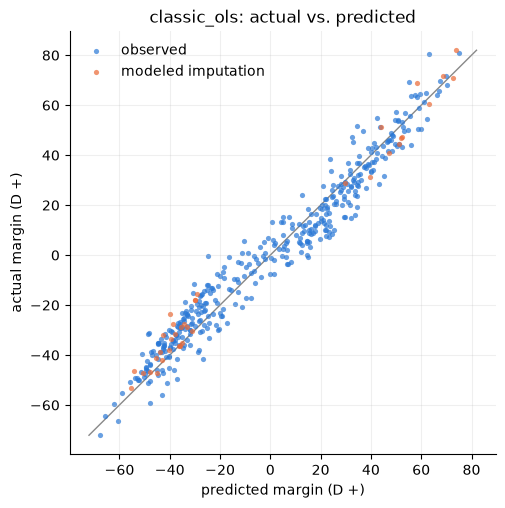

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for imputed, color, label in [(False, "#2a78d6", "observed"), (True, "#eb6834", "modeled imputation")]:
    rows = scored[scored["is_imputed"] == imputed]
    ax.scatter(rows["prediction"], rows["actual"], s=14, color=color, alpha=0.7, linewidths=0, label=label)
lim = [scored[["prediction", "actual"]].min().min(), scored[["prediction", "actual"]].max().max()]
ax.plot(lim, lim, color="#888", lw=1, zorder=0)
ax.set(xlabel="predicted margin (D +)", ylabel="actual margin (D +)", title=f"{result.config['name']}: actual vs. predicted")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## Ablations and variants (not saved)

Each variant is just a formula. `require_complete=SHARED_COLUMNS` (every predictor column any formula uses, from `evaluation.shared_columns`) makes every run use the same rows, so `compare` reports `same_train_rows` / `same_eval_rows` as True, and a metric change is a modeling change, not a sample change.

In [10]:
TARGET = "adj_margin_2p_norm"
VARIANTS = {
    "no_gen_margin_raw": f"{TARGET} ~ partisan_lean + inc_signed",
    "no_partisan_lean": f"{TARGET} ~ gen_margin_raw + inc_signed",
    "no_inc_signed": f"{TARGET} ~ gen_margin_raw + partisan_lean",
    "plus_acs": FORMULA + " + college + hispanic",
    "lean_x_inc": FORMULA + " + partisan_lean:inc_signed",
    "inc_categorical": f"{TARGET} ~ gen_margin_raw + partisan_lean + C(inc_signed)",
}
# every predictor column any formula uses: required on every run, so all runs share the same rows
SHARED_COLUMNS = evaluation.shared_columns(formulas=[FORMULA, *VARIANTS.values()], columns=predictors.columns)
print(SHARED_COLUMNS)

base = run_ols(
    formula=FORMULA,
    train_years=TRAIN_YEARS,
    eval_years=EVAL_YEARS,
    predict_years=PREDICT_YEARS,
    predictors=predictors,
    targets=targets,
    use_holdout=USE_HOLDOUT,
    require_complete=SHARED_COLUMNS,
    name="classic_ols",
    save=False,
)
variants = [
    run_ols(
        formula=formula,
        train_years=TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=SHARED_COLUMNS,
        name=name,
        save=False,
    )
    for name, formula in VARIANTS.items()
]
tracking.highlight(tracking.compare([base, *variants], full=False))  # full=True for every runs.csv column

['gen_margin_raw', 'partisan_lean', 'inc_signed', 'college', 'hispanic']


## WE WANT TO SEE EACH MODELS COEFFICIENTS TOO!

In [11]:
# One row per 2022 district every run predicted: its actual target (adj_margin_2p_norm) and is_imputed, then each
# run's prediction for that district, one column per run (named as in compare above)
tracking.compare_predictions([base, *variants]).head()

,year,state,district,actual,is_imputed,classic_ols,no_gen_margin_raw,no_partisan_lean,no_inc_signed,plus_acs,lean_x_inc,inc_categorical
0,2022,AK,0,-0.320239,False,-2.877423,1.234818,27.884311,-18.571310,-2.961578,-2.477789,-2.863782
1,2022,AL,1,-37.974972,True,-40.121972,-35.209128,-31.100041,-36.809397,-40.152955,-40.480223,-40.111959
2,2022,AL,2,-40.642745,False,-41.511027,-36.602646,-31.100041,-38.643997,-41.525627,-41.912891,-41.500813
3,2022,AL,3,-47.826514,False,-44.844762,-39.947090,-31.100041,-43.047038,-44.839608,-45.351294,-44.834064
4,2022,AL,4,-72.099149,False,-67.527227,-62.702419,-31.100041,-73.004984,-67.452398,-68.745918,-67.513242


In [12]:
# The same table with each run's residual (actual - prediction) instead: positive means the run under-predicted the
# Democratic margin. Sorted by the base run's worst misses; sort by another run's column, or filter to one district,
# e.g. residuals.query("state == 'CA' and district == 13")
residuals = tracking.compare_predictions([base, *variants], values="residual")
residuals.sort_values("classic_ols", key=abs, ascending=False).head(10)

,year,state,district,actual,is_imputed,classic_ols,no_gen_margin_raw,no_partisan_lean,no_inc_signed,plus_acs,lean_x_inc,inc_categorical
75,2022,CO,3,-0.166905,False,24.577401,19.615159,30.933136,16.332386,24.572471,24.452841,24.569617
188,2022,MD,1,-11.587650,False,18.941665,13.998007,19.512391,12.552212,19.066132,18.998737,18.933043
191,2022,MD,4,80.651467,False,17.574002,12.789770,82.259332,-3.363763,17.543522,16.671320,17.649390
58,2022,CA,38,16.183144,False,-17.463433,-21.693001,-11.701167,-13.484746,-17.687400,-17.341932,-17.471779
260,2022,NJ,8,51.698778,False,17.317573,12.625523,53.306643,5.584235,17.250277,16.660655,17.388802
55,2022,CA,35,14.729712,False,-17.266339,-21.490605,-13.154599,-12.758241,-17.629328,-17.168389,-17.274925
433,2022,WV,2,-31.137267,False,17.237331,12.350998,-0.037226,16.571815,17.280305,17.854689,17.226122
128,2022,GA,14,-31.729314,False,17.053830,12.168809,-0.629273,16.519356,16.996682,17.684015,17.042561
232,2022,MT,2,-23.428159,True,16.416001,11.502266,7.671882,13.014318,16.497567,16.765530,16.406029
95,2022,FL,9,7.270912,False,-16.112992,-20.309594,-20.613398,-8.842518,-16.232734,-16.137922,-16.122827


In [13]:
# The predictions for the base run's 10 worst residuals (same order): actual, then each run's prediction
worst = residuals.sort_values("classic_ols", key=abs, ascending=False).head(10)
predictions = tracking.compare_predictions([base, *variants])
worst[["year", "state", "district"]].merge(predictions, on=["year", "state", "district"])

,year,state,district,actual,is_imputed,classic_ols,no_gen_margin_raw,no_partisan_lean,no_inc_signed,plus_acs,lean_x_inc,inc_categorical
0,2022,CO,3,-0.166905,False,-24.744306,-19.782064,-31.100041,-16.499291,-24.739376,-24.619746,-24.736522
1,2022,MD,1,-11.587650,False,-30.529315,-25.585657,-31.100041,-24.139862,-30.653782,-30.586386,-30.520693
2,2022,MD,4,80.651467,False,63.077465,67.861698,-1.607865,84.015230,63.107945,63.980147,63.002077
3,2022,CA,38,16.183144,False,33.646577,37.876145,27.884311,29.667890,33.870544,33.525076,33.654923
4,2022,NJ,8,51.698778,False,34.381205,39.073255,-1.607865,46.114543,34.448501,35.038123,34.309976
5,2022,CA,35,14.729712,False,31.996051,36.220318,27.884311,27.487953,32.359040,31.898101,32.004637
6,2022,WV,2,-31.137267,False,-48.374598,-43.488265,-31.100041,-47.709082,-48.417573,-48.991956,-48.363389
7,2022,GA,14,-31.729314,False,-48.783144,-43.898123,-31.100041,-48.248670,-48.725996,-49.413329,-48.771875
8,2022,MT,2,-23.428159,True,-39.844160,-34.930425,-31.100041,-36.442477,-39.925726,-40.193689,-39.834188
9,2022,FL,9,7.270912,False,23.383905,27.580506,27.884311,16.113430,23.503647,23.408835,23.393739


## FEC fundraising (`fec_f`)

`fec_f.csv` comes from `data/processed/house_fec.csv` (`data-processing/fec_finance.py`), prepared by `house_features.py`:

- `fundraising_advantage`, `spending_advantage`: `log1p(D) - log1p(R)` of receipts / disbursements, capped at ±5 (a 148:1 ratio). Uncapped, a funded nominee against one with no money gives about ±14, which would dominate the fit.
- `small_dollar_share_diff`: the D − R unitemized share of individual contributions. Blank in 2006 (not in that year's FEC file), and wherever a share is undefined.

**Caveats:**

- **Timing:** 2006–2024 totals are FEC's full-cycle summaries, through December 31, so they include post-election money. 2026 runs through mid-October. The model learns from end-of-cycle money and forecasts from pre-election money.
- **Excluded rows:** a few rows are blank and left out (`missing:<var>` in `excluded`): six 2022–2024 winners FEC has no data for (`FEC_KNOWN_GAPS`) and the 2026 races with an unresolved nominee.

The FEC variants share their rows (`FEC_SHARED_COLUMNS`), as in the ablations above.

In [19]:
FEC_VARIANTS = {
    "plus_fundraising": FORMULA + " + fundraising_advantage",
    "plus_spending": FORMULA + " + spending_advantage",
    "plus_fundraising_spending": FORMULA + " + fundraising_advantage + spending_advantage",
    "plus_fundraising_no_inc": f"{TARGET} ~ gen_margin_raw + partisan_lean + fundraising_advantage",
}
FEC_SHARED_COLUMNS = evaluation.shared_columns(formulas=[FORMULA, *FEC_VARIANTS.values()], columns=predictors.columns)
print(FEC_SHARED_COLUMNS)

fec_base = run_ols(
    formula=FORMULA,
    train_years=TRAIN_YEARS,
    eval_years=EVAL_YEARS,
    predict_years=PREDICT_YEARS,
    predictors=predictors,
    targets=targets,
    use_holdout=USE_HOLDOUT,
    require_complete=FEC_SHARED_COLUMNS,
    name="classic_ols",
    save=False,
)
fec_variants = [
    run_ols(
        formula=formula,
        train_years=TRAIN_YEARS,
        eval_years=EVAL_YEARS,
        predict_years=PREDICT_YEARS,
        predictors=predictors,
        targets=targets,
        use_holdout=USE_HOLDOUT,
        require_complete=FEC_SHARED_COLUMNS,
        name=name,
        save=False,
    )
    for name, formula in FEC_VARIANTS.items()
]
tracking.highlight(tracking.compare([fec_base, *fec_variants], full=False))

['gen_margin_raw', 'partisan_lean', 'inc_signed', 'fundraising_advantage', 'spending_advantage']


/var/folders/ln/mpvh0mhs1vg1qh10s96jznxc0000gn/T/ipykernel_51778/1983250087.py:10: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                       
eval  missing:fundraising_advantage    2
      missing:spending_advantage       1
  fec_base = run_ols(
/var/folders/ln/mpvh0mhs1vg1qh10s96jznxc0000gn/T/ipykernel_51778/1983250087.py:23: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                       
eval  missing:fundraising_advantage    2
      missing:spending_advantage       1
  run_ols(
/var/folders/ln/mpvh0mhs1vg1qh10s96jznxc0000gn/T/ipykernel_51778/1983250087.py:23: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                    
eval  missing:spending_advantage    3
  run_ols(
/var/folders/ln/mpvh0mhs1vg1qh10s96jznxc0000gn/T/ipykernel_51778/1983250087.py:23: UserWarning: Rows excluded for missing or nonfinite predictors:
role  reason                       
eval  missing:fundraising

In [20]:
import pandas as pd

# each run's coefficients (rows: terms, columns: runs); blank where a run doesn't use the term
pd.concat({run.config["name"]: run.coefficients["coef"] for run in [fec_base, *fec_variants]}, axis=1)

,classic_ols,plus_fundraising,plus_spending,plus_fundraising_spending,plus_fundraising_no_inc
term,,,,,
Intercept,-0.483251,-0.152351,-0.222707,-0.156739,-0.152351
gen_margin_raw,0.827346,0.584846,0.604156,0.585822,0.584846
partisan_lean,0.817092,0.647954,0.650314,0.647863,0.647954
inc_signed,11.717850,6.002409,6.148042,6.003921,6.002409
fundraising_advantage,NaN,3.597082,NaN,3.352669,3.597082
spending_advantage,NaN,NaN,3.572352,0.248110,NaN


In [21]:
# small_dollar_share_diff has no 2006 data, so this comparison trains from 2008, on the rows both formulas can use
SMALL_DOLLAR_TRAIN_YEARS = [2008, 2010, 2012, 2014, 2016, 2018, 2020]
SMALL_DOLLAR_FORMULA = FORMULA + " + fundraising_advantage + small_dollar_share_diff"
SMALL_DOLLAR_SHARED_COLUMNS = evaluation.shared_columns(formulas=[FORMULA, SMALL_DOLLAR_FORMULA],
                                                        columns=predictors.columns)

small_dollar_base = run_ols(
    formula=FORMULA,
    train_years=SMALL_DOLLAR_TRAIN_YEARS,
    eval_years=EVAL_YEARS,
    predict_years=PREDICT_YEARS,
    predictors=predictors,
    targets=targets,
    use_holdout=USE_HOLDOUT,
    require_complete=SMALL_DOLLAR_SHARED_COLUMNS,
    name="classic_ols_from_2008",
    save=False,
)
small_dollar = run_ols(
    formula=SMALL_DOLLAR_FORMULA,
    train_years=SMALL_DOLLAR_TRAIN_YEARS,
    eval_years=EVAL_YEARS,
    predict_years=PREDICT_YEARS,
    predictors=predictors,
    targets=targets,
    use_holdout=USE_HOLDOUT,
    require_complete=SMALL_DOLLAR_SHARED_COLUMNS,
    name="plus_fundraising_small_dollar",
    save=False,
)
tracking.highlight(tracking.compare([small_dollar_base, small_dollar], full=False))

/var/folders/ln/mpvh0mhs1vg1qh10s96jznxc0000gn/T/ipykernel_51778/885449801.py:7: UserWarning: Rows excluded for missing or nonfinite predictors:
role   reason                         
eval   missing:fundraising_advantage        2
       missing:small_dollar_share_diff     77
train  missing:small_dollar_share_diff    408
  small_dollar_base = run_ols(
/var/folders/ln/mpvh0mhs1vg1qh10s96jznxc0000gn/T/ipykernel_51778/885449801.py:19: UserWarning: Rows excluded for missing or nonfinite predictors:
role   reason                         
eval   missing:fundraising_advantage        2
       missing:small_dollar_share_diff     77
train  missing:small_dollar_share_diff    408
  small_dollar = run_ols(


## Saved runs

Save the runs worth keeping: `tracking.save_run(result)` or `run_experiment(..., save=True)`. Each gets a folder in `results/house/runs/` and a row in `results/house/runs.csv`; the CLI saves by default.

In [17]:
# run_id = tracking.save_run(result)  # or run_ols(..., save=True)

In [18]:
runs = tracking.load_runs()  # after at least one saved run
runs.sort_values("mae_non_imputed")[["run_id", "formula", "n_train", "mae_non_imputed", "rmse_non_imputed",
                                      "bias_non_imputed", "mae_imputed", "mae_all"]]

FileNotFoundError: [Errno 2] No such file or directory: '/Users/ElijahSong/Documents/Election26/results/house/runs.csv'

In [ ]:
saved = tracking.load_run(runs["run_id"].iloc[-1])  # config, metrics, counts, fit, coefficients, predictions, excluded
saved.coefficients

In [ ]:
tracking.highlight(tracking.compare(runs["run_id"].tail(3).tolist()))